

# Visualize source time courses (stcs)

This tutorial focuses on visualization of :term:`source estimates <STC>`.

## Surface Source Estimates
First, we get the paths for the evoked data and the source time courses (stcs).


In [ ]:
# Authors: The MNE-Python contributors.
# License: BSD-3-Clause
# Copyright the MNE-Python contributors.

In [3]:
import matplotlib.pyplot as plt
import numpy as np

import mne
from mne import read_evokeds
from mne.datasets import fetch_hcp_mmp_parcellation, sample
from mne.minimum_norm import apply_inverse, read_inverse_operator

data_path = sample.data_path()
meg_path = data_path / "MEG" / "sample"
subjects_dir = data_path / "subjects"

fname_evoked = meg_path / "sample_audvis-ave.fif"
fname_stc = meg_path / "sample_audvis-meg"
fetch_hcp_mmp_parcellation(subjects_dir)

  0%|                                              | 0.00/1.32M [00:00<?, ?B/s]

  0%|                                              | 0.00/1.32M [00:00<?, ?B/s]

Creating combined labels
Reading labels from parcellation...
   read 181 labels from C:\Users\alber\mne_data\MNE-sample-data\subjects\fsaverage\label\lh.HCPMMP1.annot
Reading labels from parcellation...
   read 181 labels from C:\Users\alber\mne_data\MNE-sample-data\subjects\fsaverage\label\rh.HCPMMP1.annot
Writing labels to parcellation...
   writing 23 labels to C:\Users\alber\mne_data\MNE-sample-data\subjects\fsaverage\label\lh.HCPMMP1_combined.annot
Writing labels to parcellation...
   writing 23 labels to C:\Users\alber\mne_data\MNE-sample-data\subjects\fsaverage\label\rh.HCPMMP1_combined.annot


Then, we read the stc from file.



In [4]:
stc = mne.read_source_estimate(fname_stc, subject="sample")

This is a :class:`SourceEstimate <mne.SourceEstimate>` object.



In [5]:
print(stc)

<SourceEstimate | 7498 vertices, subject : sample, tmin : 0.0 (ms), tmax : 240.0 (ms), tstep : 10.0 (ms), data shape : (7498, 25), ~791 KiB>


The SourceEstimate object is in fact a *surface* source estimate. MNE also
supports volume-based source estimates but more on that later.

We can plot the source estimate using the
:func:`stc.plot <mne.SourceEstimate.plot>` just as in other MNE
objects. Note that for this visualization to work, you must have ``PyVista``
installed on your machine.



In [6]:
initial_time = 0.1
brain = stc.plot(
    subjects_dir=subjects_dir,
    initial_time=initial_time,
    clim=dict(kind="value", lims=[3, 6, 9]),
    smoothing_steps=7,
)

Using pyvistaqt 3d backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


You can also morph it to fsaverage and visualize it using a flatmap.



In [7]:
stc_fs = mne.compute_source_morph(
    stc, "sample", "fsaverage", subjects_dir, smooth=5, verbose="error"
).apply(stc)
brain = stc_fs.plot(
    subjects_dir=subjects_dir,
    initial_time=initial_time,
    clim=dict(kind="value", lims=[3, 6, 9]),
    surface="flat",
    hemi="both",
    size=(1000, 500),
    smoothing_steps=5,
    time_viewer=False,
    add_data_kwargs=dict(colorbar_kwargs=dict(label_font_size=10)),
)

# to help orient us, let's add a parcellation (red=auditory, green=motor,
# blue=visual)
brain.add_annotation("HCPMMP1_combined", borders=2)

# You can save a movie like the one on our documentation website with:
# brain.save_movie(time_dilation=20, tmin=0.05, tmax=0.16,
#                  interpolation='linear', framerate=10)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Reading labels from parcellation...
   read 23 labels from C:\Users\alber\mne_data\MNE-sample-data\subjects\fsaverage\label\lh.HCPMMP1_combined.annot
Reading labels from parcellation...
   read 23 labels from C:\Users\alber\mne_data\MNE-sample-data\subjects\fsaverage\label\rh.HCPMMP1_combined.annot


Note that here we used ``initial_time=0.1``, but we can also browse through
time using ``time_viewer=True``.



## Volume Source Estimates
We can also visualize volume source estimates (used for deep structures).

Let us load the sensor-level evoked data. We select the MEG channels
to keep things simple.



In [8]:
evoked = read_evokeds(fname_evoked, condition=0, baseline=(None, 0))
evoked.pick(picks="meg").crop(0.05, 0.15)
# this risks aliasing, but these data are very smooth
evoked.decimate(10, verbose="error")

Reading C:\Users\alber\mne_data\MNE-sample-data\MEG\sample\sample_audvis-ave.fif ...
    Read a total of 4 projection items:
        PCA-v1 (1 x 102) active
        PCA-v2 (1 x 102) active
        PCA-v3 (1 x 102) active
        Average EEG reference (1 x 60) active
    Found the data of interest:
        t =    -199.80 ...     499.49 ms (Left Auditory)
        0 CTF compensation matrices available
        nave = 55 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Applying baseline correction (mode: mean)


<Evoked | 'Left Auditory' (average, N=55), 0.049949 – 0.14985 s, baseline -0.199795 – 0 s (baseline period was cropped after baseline correction), 306 ch, ~3.2 MiB>

Then, we can load the precomputed inverse operator from a file.



In [9]:
fname_inv = meg_path / "sample_audvis-meg-vol-7-meg-inv.fif"
inv = read_inverse_operator(fname_inv)
src = inv["src"]
mri_head_t = inv["mri_head_t"]

Reading inverse operator decomposition from C:\Users\alber\mne_data\MNE-sample-data\MEG\sample\sample_audvis-meg-vol-7-meg-inv.fif...
    Reading inverse operator info...
    [done]
    Reading inverse operator decomposition...
    [done]
    305 x 305 full covariance (kind = 1) found.
    Read a total of 4 projection items:
        PCA-v1 (1 x 102) active
        PCA-v2 (1 x 102) active
        PCA-v3 (1 x 102) active
        Average EEG reference (1 x 60) active
    Noise covariance matrix read.
    11271 x 11271 diagonal covariance (kind = 2) found.
    Source covariance matrix read.
    Did not find the desired covariance matrix (kind = 6)
    11271 x 11271 diagonal covariance (kind = 5) found.
    Depth priors read.
    Did not find the desired covariance matrix (kind = 3)
    Reading a source space...
    [done]
    1 source spaces read
    Read a total of 4 projection items:
        PCA-v1 (1 x 102) active
        PCA-v2 (1 x 102) active
        PCA-v3 (1 x 102) active
        A

The source estimate is computed using the inverse operator and the
sensor-space data.



In [10]:
snr = 3.0
lambda2 = 1.0 / snr**2
method = "dSPM"  # use dSPM method (could also be MNE or sLORETA)
stc = apply_inverse(evoked, inv, lambda2, method)
del inv

Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 55
    Created the regularized inverter
    Created an SSP operator (subspace dimension = 3)
    Created the whitener using a noise covariance matrix with rank 302 (3 small eigenvalues omitted)
    Computing noise-normalization factors (dSPM)...
[done]
Applying inverse operator to "Left Auditory"...
    Picked 305 channels from the data
    Computing inverse...
    Eigenleads need to be weighted ...
    Computing residual...
    Explained  77.1% variance
    Combining the current components...
    dSPM...
[done]


This time, we have a different container
(:class:`VolSourceEstimate <mne.VolSourceEstimate>`) for the source time
course.



In [11]:
print(stc)

<VolSourceEstimate | 3757 vertices, subject : sample, tmin : 49.94880328959697 (ms), tmax : 149.84640986879091 (ms), tstep : 16.649601096532322 (ms), data shape : (3757, 7), ~235 KiB>


This too comes with a convenient plot method.



Showing: t = 0.100 s, (-47.3, -19.0, -6.3) mm, [4, 9, 10] vox, 5653 vertex
Using control points [ 7.67635542  9.11717401 20.19136023]


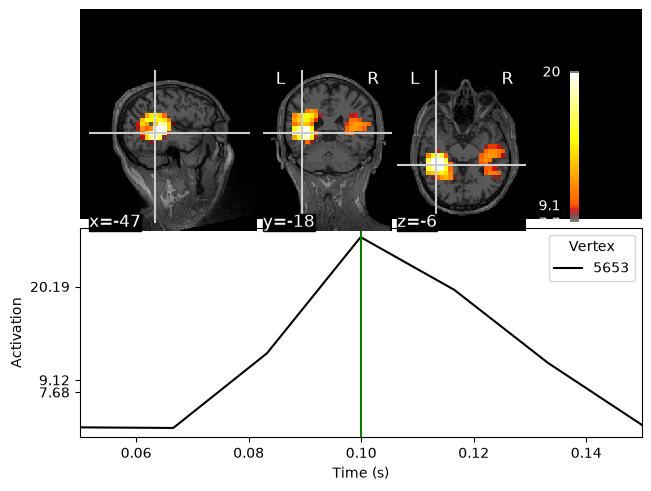

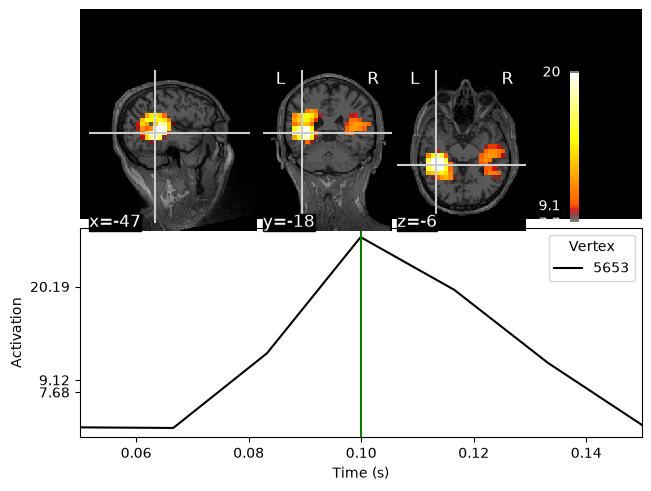

In [14]:
stc.plot(src, subject="sample", subjects_dir=subjects_dir)

For this visualization, ``nilearn`` must be installed.
This visualization is interactive. Click on any of the anatomical slices
to explore the time series. Clicking on any time point will bring up the
corresponding anatomical map.

We could visualize the source estimate on a glass brain. Unlike the previous
visualization, a glass brain does not show us one slice but what we would
see if the brain was transparent like glass, and
:term:`maximum intensity projection`) is used:



Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.022485 -0.008449 -0.036217       5.60 mm
    0.071071 0.914866 0.406098     -19.82 mm
    0.008756 -0.433700 1.028119      -1.55 mm
    0.000000 0.000000 0.000000       1.00

Showing: t = 0.100 s, (-42.4, -43.1, -0.2) mm, [4, 9, 10] vox, 5653 vertex
Using control points [ 7.67635542  9.11717401 20.19136023]


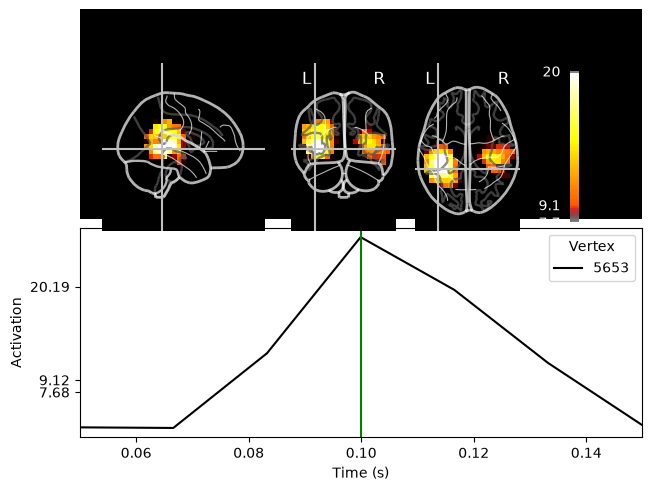

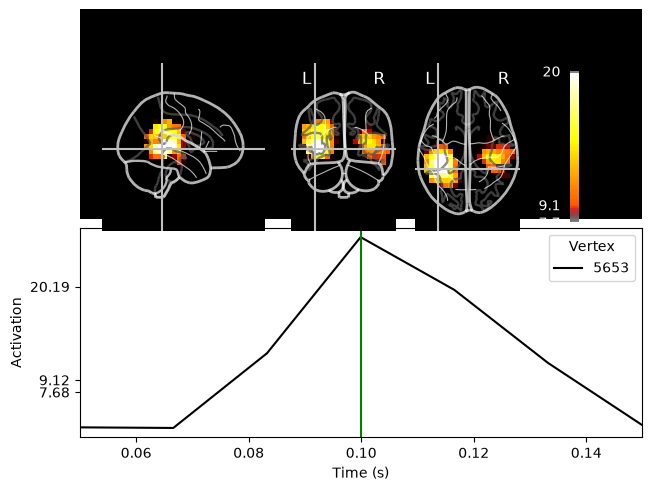

In [15]:
stc.plot(src, subject="sample", subjects_dir=subjects_dir, mode="glass_brain")

You can also extract label time courses using volumetric atlases. Here we'll
use the built-in ``aparc+aseg.mgz``:



Reading atlas C:\Users\alber\mne_data\MNE-sample-data\subjects\sample\mri\aparc+aseg.mgz
114/114 atlas regions had at least one vertex in the source space
Extracting time courses for 114 labels (mode: mean)


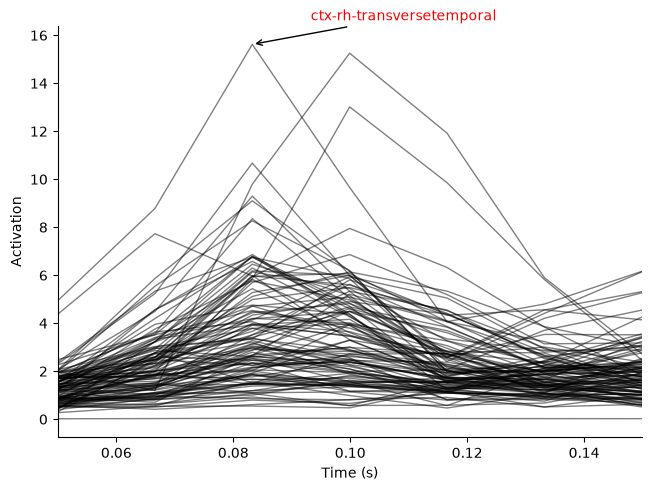

In [16]:
fname_aseg = subjects_dir / "sample" / "mri" / "aparc+aseg.mgz"
label_names = mne.get_volume_labels_from_aseg(fname_aseg)
label_tc = stc.extract_label_time_course(fname_aseg, src=src)

lidx, tidx = np.unravel_index(np.argmax(label_tc), label_tc.shape)
fig, ax = plt.subplots(1, layout="constrained")
ax.plot(stc.times, label_tc.T, "k", lw=1.0, alpha=0.5)
xy = np.array([stc.times[tidx], label_tc[lidx, tidx]])
xytext = xy + [0.01, 1]
ax.annotate(label_names[lidx], xy, xytext, arrowprops=dict(arrowstyle="->"), color="r")
ax.set(xlim=stc.times[[0, -1]], xlabel="Time (s)", ylabel="Activation")
for key in ("right", "top"):
    ax.spines[key].set_visible(False)

We can plot several labels with the most activation in their time course
for a more fine-grained view of the anatomical loci of activation.



In [17]:
labels = [
    label_names[idx]
    for idx in np.argsort(label_tc.max(axis=1))[:7]
    if "unknown" not in label_names[idx].lower()
]  # remove catch-all
brain = mne.viz.Brain(
    "sample",
    hemi="both",
    surf="pial",
    alpha=0.5,
    cortex="low_contrast",
    subjects_dir=subjects_dir,
)
brain.add_volume_labels(aseg="aparc+aseg", labels=labels)
brain.show_view(azimuth=250, elevation=40, distance=400)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
    Smoothing by a factor of 0.9


And we can project these label time courses back to their original
locations and see how the plot has been smoothed:



Reading atlas C:\Users\alber\mne_data\MNE-sample-data\subjects\sample\mri\aparc+aseg.mgz
114/114 atlas regions had at least one vertex in the source space
Extracting time courses for 114 labels (mode: mean)
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.022485 -0.008449 -0.036217       5.60 mm
    0.071071 0.914866 0.406098     -19.82 mm
    0.008756 -0.433700 1.028119      -1.55 mm
    0.000000 0.000000 0.000000       1.00

Showing: t = 2.000 s, (36.1, -34.8, 7.7) mm, [15, 9, 11] vox, 6210 vertex
Using control points [ 5.69834054  5.98871778 15.62206532]


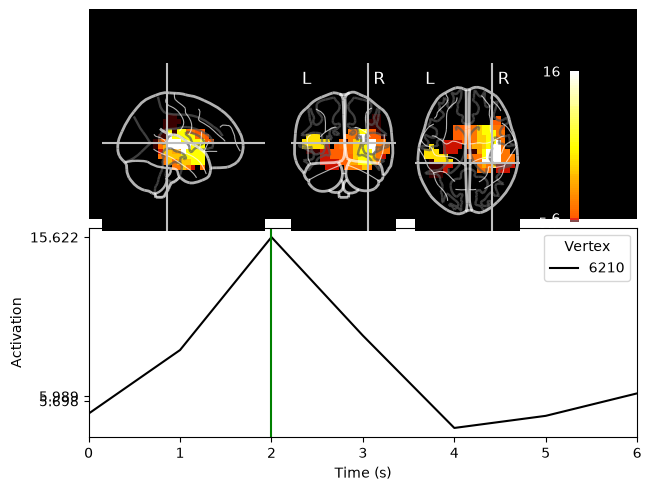

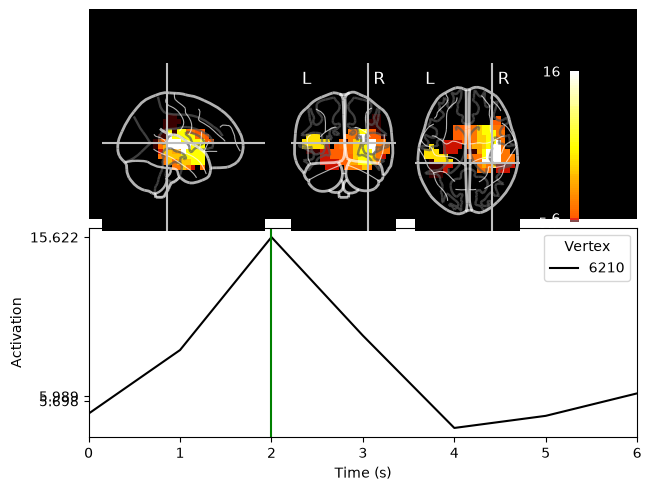

In [18]:
stc_back = mne.labels_to_stc(fname_aseg, label_tc, src=src)
stc_back.plot(src, subjects_dir=subjects_dir, mode="glass_brain")

## Vector Source Estimates
If we choose to use ``pick_ori='vector'`` in
:func:`apply_inverse <mne.minimum_norm.apply_inverse>`



In [19]:
fname_inv = data_path / "MEG" / "sample" / "sample_audvis-meg-oct-6-meg-inv.fif"
inv = read_inverse_operator(fname_inv)
stc = apply_inverse(evoked, inv, lambda2, "dSPM", pick_ori="vector")
brain = stc.plot(
    subject="sample",
    subjects_dir=subjects_dir,
    initial_time=initial_time,
    brain_kwargs=dict(silhouette=True),
    smoothing_steps=7,
)

Reading inverse operator decomposition from C:\Users\alber\mne_data\MNE-sample-data\MEG\sample\sample_audvis-meg-oct-6-meg-inv.fif...
    Reading inverse operator info...
    [done]
    Reading inverse operator decomposition...
    [done]
    305 x 305 full covariance (kind = 1) found.
    Read a total of 4 projection items:
        PCA-v1 (1 x 102) active
        PCA-v2 (1 x 102) active
        PCA-v3 (1 x 102) active
        Average EEG reference (1 x 60) active
    Noise covariance matrix read.
    22494 x 22494 diagonal covariance (kind = 2) found.
    Source covariance matrix read.
    22494 x 22494 diagonal covariance (kind = 6) found.
    Orientation priors read.
    22494 x 22494 diagonal covariance (kind = 5) found.
    Depth priors read.
    Did not find the desired covariance matrix (kind = 3)
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    Reading a source space...
    Computing 

## Dipole fits
For computing a dipole fit, we need to load the noise covariance, the BEM
solution, and the coregistration transformation files. Note that for the
other methods, these were already used to generate the inverse operator.



In [20]:
fname_cov = meg_path / "sample_audvis-cov.fif"
fname_bem = subjects_dir / "sample" / "bem" / "sample-5120-bem-sol.fif"
fname_trans = meg_path / "sample_audvis_raw-trans.fif"

Dipoles are fit independently for each time point, so let us crop our time
series to visualize the dipole fit for the time point of interest.



In [21]:
evoked.crop(0.1, 0.1)
dip = mne.fit_dipole(evoked, fname_cov, fname_bem, fname_trans)[0]

BEM               : WindowsPath('C:/Users/alber/mne_data/MNE-sample-data/subjects/sample/bem/sample-5120-bem-sol.fif')
MRI transform     : C:\Users\alber\mne_data\MNE-sample-data\MEG\sample\sample_audvis_raw-trans.fif
Head origin       :   -4.2   19.3   65.3 mm rad =   72.3 mm.
Guess grid        :   20.0 mm
Guess mindist     :    5.0 mm
Guess exclude     :   20.0 mm
Using normal MEG coil definitions.
Noise covariance  : C:\Users\alber\mne_data\MNE-sample-data\MEG\sample\sample_audvis-cov.fif

Coordinate transformation: MRI (surface RAS) -> head
    0.999310 0.009985 -0.035787      -3.17 mm
    0.012759 0.812405 0.582954       6.86 mm
    0.034894 -0.583008 0.811716      28.88 mm
    0.000000 0.000000 0.000000       1.00
Coordinate transformation: MEG device -> head
    0.991420 -0.039936 -0.124467      -6.13 mm
    0.060661 0.984012 0.167456       0.06 mm
    0.115790 -0.173570 0.977991      64.74 mm
    0.000000 0.000000 0.000000       1.00
1 bad channels total
Read 305 MEG channels f

Finally, we can visualize the dipole.



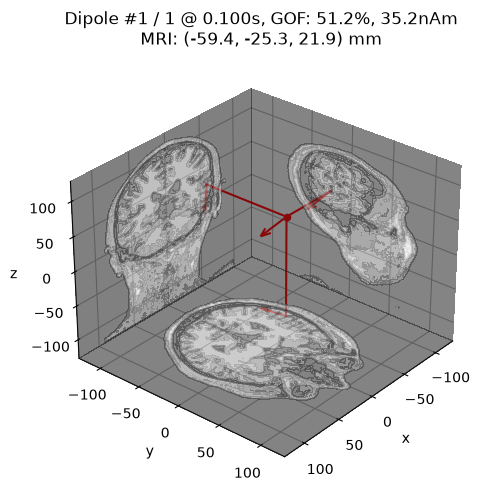

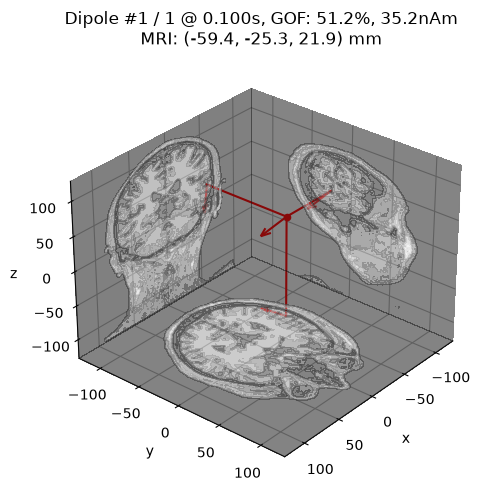

In [22]:
dip.plot_locations(fname_trans, "sample", subjects_dir)